# The F-19 planner, end to end: from briefing to a route ranked by career points

How a mission becomes a route, in the order the code does it, with runnable cells and plots. It covers the **faster planner** (memoised
search, process pool, loiter as an opt-in post-pass) and the two new ways of ranking the options: **points** (expected career points)
and **aircraft** (points with enemy fighters modelled). The longer, older tour of each internal stage is `planner_walkthrough.ipynb`.

```
 briefing (mission_mem.json) + plan.json
   1 World / RadarModel        the map, radars, SA-14 cells; "is the plane seen here?" from the game's own radar rules
   2 Router + Planner.plan     grid A* -> corner reduction -> repair -> fuel walk in game time: ONE route for ONE sequence of pieces
   3 alert simulation          what the radars do with that route, pulse by pulse (network alerts, launches, IDs)
   4 options                   target order x approach side x attack bearings (+ primary only): each is planned
   5 ranking  (Planner.rank)   cost  |  points  |  aircraft            <- the choice of objective
   6 outputs                   route.json for the autopilot, report.txt
```
Cells marked **slow** plan whole missions (25-60 s each); set `RUN_SLOW = True` to run them. Units: 64 game units per km, plots north-up.


In [1]:
import json, math, re, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle

from f19.core.settings import settings as S
from f19.planner import profiles, fuelplan, alertsim, report, loiter, api
from f19.planner.planner import Planner
from f19.planner.router import hdg, unit, from_hdg, nearest_dir, MOVES, DIR_ANG
from f19.planner.world import K, CELL_KM, GROUND_KMH_PER_KT
from f19.planner.estimate import FuelConstraint

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 9})

FIXTURES = S.data / "fixtures/plans"
print("data:", S.data)
print("plans:", sorted(p.name for p in FIXTURES.iterdir()))

data: /Users/robmaxwell/f19-data
plans: ['ce_budejovice_1023_1811', 'ce_kolobrzeg_1022_2250', 'ce_liberec_1027_0916', 'pg_shiraz_1024_1514']


## Setup: a plan and the plotting helpers
`PLAN` is the example used throughout. Veteran is our default level; Elite the stretch goal; the plan's `settings.opponent` says which this is.

In [2]:
PLAN = "ce_kolobrzeg_1022_2250"     # try: pg_shiraz_1024_1514, ce_liberec_1027_0916, ce_budejovice_1023_1811
RUN_SLOW = True  # True: also run the whole-mission planning cells (slow)                    # True: also run the 30 s - 3 min cells

def load_plan(name):
    D = FIXTURES / name
    spec = json.load(open(D / "plan.json"))
    mission = json.load(open(D / "mission_mem.json"))
    route = json.load(open(D / "route.json"))              # what the planner produced (stored)
    spec = {**spec, "takeoff_heading": api.resolve_takeoff_heading(spec, mission)}
    return D, spec, mission, route

_planners = {}
def get_planner(name, loiters=False, **spec_over):
    """Planner for a fixture (cached). spec_over: keys merged into plan.json, e.g. profile="fast"."""
    key = (name, loiters, json.dumps(spec_over, sort_keys=True, default=str))
    if key not in _planners:
        D, spec, M, _ = load_plan(name)
        _planners[key] = Planner({**spec, **spec_over}, M, str(D), loiters=loiters)
    return _planners[key]

def chosen_sequence(pl, chosen):
    """Rebuild the planner's sequence for a stored 'chosen' tag, e.g.
    'order primary/secondary, approach S, primary photo on 90, secondary photo on 270'."""
    order = re.search(r"order ([\w/]+)", chosen).group(1).split("/")
    side = re.search(r"approach ([NS])", chosen).group(1)
    seq = [pl.takeoff(), *pl.targets(order), pl.landing(side)]
    tg = {t["role"].rstrip("?"): t for t in pl.M["targets"]}
    for k, el in enumerate(seq):
        if el["t"] == "target":
            m = re.search(rf"{el['role']} (photo|maverick) on (\d+)", chosen)
            if m: seq[k] = pl.attack_piece(el, tg[el["role"]], m.group(1), float(m.group(2)))
    return seq

D, spec, M, stored = load_plan(PLAN)
pl = get_planner(PLAN)
print(PLAN, "->", stored["chosen"])
print("targets:", [(t["role"], t["task"], t["object"], t["place"]) for t in M["targets"]])

ce_kolobrzeg_1022_2250 -> order primary/secondary, approach S, primary photo on 90, secondary photo on 270
targets: [('primary', 'photograph', 'SAM Radar', 'Kolobrzeg'), ('secondary', 'photograph', 'Tank Farm', 'Liberec')]


In [3]:
# --- plotting helpers (km, north up) ---------------------------------------------------------------------------
def km(a): return np.asarray(a, float) / K

def xy_of(pts):
    """Accepts planner points [(xy, label, attrs)], route.json point dicts, or a bare xy list."""
    out = []
    for p in pts:
        if isinstance(p, dict): out.append((p["x"], p["y"]))
        elif len(p) == 3 and not np.isscalar(p[0]): out.append(tuple(p[0]))
        else: out.append(tuple(p))
    return km(out)

def draw_world(ax, pl, crop=None, terrain=True, territory=True, sa14=True, radars=True, bases=True, targets=True, labels=True):
    W = pl.W; L = W.size / K
    if terrain: ax.imshow(np.minimum(W.H, 3000), cmap="Greys", vmax=4500, extent=(0, L, L, 0), alpha=.75, interpolation="nearest")
    if territory:
        ax.imshow(np.where(W.enemy_grid, 1.0, np.nan), cmap=ListedColormap(["#d62728"]), alpha=.10, extent=(0, L, L, 0))
    if sa14 and W.sa14_cells.any():
        for cy, cx in zip(*np.nonzero(W.sa14_cells)):
            ax.add_patch(plt.Rectangle((cx * 32, cy * 32), 32, 32, fc="#ff7f0e", alpha=.25, ec="#ff7f0e", lw=.5))
    if bases:
        for n, (x, y) in W.airbases.items():
            ax.plot(x / K, y / K, "s", c="#1f77b4", ms=4)
            if labels: ax.annotate(n, (x / K, y / K), xytext=(3, 3), textcoords="offset points", fontsize=6.5, color="#1f77b4")
    if radars:
        for r in W.radars:
            ax.plot(r["x"] / K, r["y"] / K, "^" if r["type"] == "P" else "v", c="#d62728", ms=5)
            if labels: ax.annotate(f"{r['place']} {r['system']}", (r["x"] / K, r["y"] / K), xytext=(3, -8), textcoords="offset points", fontsize=6, color="#d62728")
    if targets:
        for t in pl.M["targets"]:
            ax.plot(t["x"] / K, t["y"] / K, "*", c="gold", mec="k", ms=11, zorder=5)
            if labels: ax.annotate(t["role"].rstrip("?").upper(), (t["x"] / K, t["y"] / K), xytext=(5, 5), textcoords="offset points", fontsize=7, weight="bold")
    ax.set_xlim(0, L); ax.set_ylim(L, 0); ax.set_aspect("equal")
    if crop: ax.set_xlim(crop[0], crop[1]); ax.set_ylim(crop[3], crop[2])
    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km, south)")

def draw_route(ax, pts, color="C0", lw=1.4, label=None, dots=False, **kw):
    a = xy_of(pts)
    ax.plot(a[:, 0], a[:, 1], "-", c=color, lw=lw, label=label, zorder=4, **kw)
    if dots: ax.plot(a[:, 0], a[:, 1], ".", c=color, ms=3, zorder=4)

def bbox_of(pts, pad=15):
    a = xy_of(pts); return (a[:, 0].min() - pad, a[:, 0].max() + pad, a[:, 1].min() - pad, a[:, 1].max() + pad)

def show_map(title, pl=pl, routes=(), crop=None, size=(9, 9), **kw):
    fig, ax = plt.subplots(figsize=size)
    draw_world(ax, pl, crop, **kw)
    for r in routes: draw_route(ax, **r)
    ax.set_title(title)
    if any(r.get("label") for r in routes): ax.legend(loc="lower left", fontsize=7)
    return fig, ax

In [4]:
# --- plotting helpers (km, north up) ---------------------------------------------------------------------------
def km(a): return np.asarray(a, float) / K

def xy_of(pts):
    """Accepts planner points [(xy, label, attrs)], route.json point dicts, or a bare xy list."""
    out = []
    for p in pts:
        if isinstance(p, dict): out.append((p["x"], p["y"]))
        elif len(p) == 3 and not np.isscalar(p[0]): out.append(tuple(p[0]))
        else: out.append(tuple(p))
    return km(out)

def draw_world(ax, pl, crop=None, terrain=True, territory=True, sa14=True, radars=True, bases=True, targets=True, labels=True):
    W = pl.W; L = W.size / K
    if terrain: ax.imshow(np.minimum(W.H, 3000), cmap="Greys", vmax=4500, extent=(0, L, L, 0), alpha=.75, interpolation="nearest")
    if territory:
        ax.imshow(np.where(W.enemy_grid, 1.0, np.nan), cmap=ListedColormap(["#d62728"]), alpha=.10, extent=(0, L, L, 0))
    if sa14 and W.sa14_cells.any():
        for cy, cx in zip(*np.nonzero(W.sa14_cells)):
            ax.add_patch(plt.Rectangle((cx * 32, cy * 32), 32, 32, fc="#ff7f0e", alpha=.25, ec="#ff7f0e", lw=.5))
    if bases:
        for n, (x, y) in W.airbases.items():
            ax.plot(x / K, y / K, "s", c="#1f77b4", ms=4)
            if labels: ax.annotate(n, (x / K, y / K), xytext=(3, 3), textcoords="offset points", fontsize=6.5, color="#1f77b4")
    if radars:
        for r in W.radars:
            ax.plot(r["x"] / K, r["y"] / K, "^" if r["type"] == "P" else "v", c="#d62728", ms=5)
            if labels: ax.annotate(f"{r['place']} {r['system']}", (r["x"] / K, r["y"] / K), xytext=(3, -8), textcoords="offset points", fontsize=6, color="#d62728")
    if targets:
        for t in pl.M["targets"]:
            ax.plot(t["x"] / K, t["y"] / K, "*", c="gold", mec="k", ms=11, zorder=5)
            if labels: ax.annotate(t["role"].rstrip("?").upper(), (t["x"] / K, t["y"] / K), xytext=(5, 5), textcoords="offset points", fontsize=7, weight="bold")
    ax.set_xlim(0, L); ax.set_ylim(L, 0); ax.set_aspect("equal")
    if crop: ax.set_xlim(crop[0], crop[1]); ax.set_ylim(crop[3], crop[2])
    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km, south)")

def draw_route(ax, pts, color="C0", lw=1.4, label=None, dots=False, **kw):
    a = xy_of(pts)
    ax.plot(a[:, 0], a[:, 1], "-", c=color, lw=lw, label=label, zorder=4, **kw)
    if dots: ax.plot(a[:, 0], a[:, 1], ".", c=color, ms=3, zorder=4)

def bbox_of(pts, pad=15):
    a = xy_of(pts); return (a[:, 0].min() - pad, a[:, 0].max() + pad, a[:, 1].min() - pad, a[:, 1].max() + pad)

def show_map(title, pl=pl, routes=(), crop=None, size=(9, 9), **kw):
    fig, ax = plt.subplots(figsize=size)
    draw_world(ax, pl, crop, **kw)
    for r in routes: draw_route(ax, **r)
    ax.set_title(title)
    if any(r.get("label") for r in routes): ax.legend(loc="lower left", fontsize=7)
    return fig, ax

In [5]:
from f19.planner import points, fighters
from f19.rules import radar as rg
print(PLAN, "| opponent:", spec["settings"]["opponent"], "| profile:", spec["profile"], "| objective in the profile:", pl.P["objective"])

ce_kolobrzeg_1022_2250 | opponent: elite | profile: stealth | objective in the profile: cost


## 1. The world the planner sees
Terrain walls (grey), enemy territory (red tint), live SA-14 cells by day (orange), friendly airbases (blue), radar sites (red triangles), targets (stars).
Everything the routing rules reason about is on this one map.

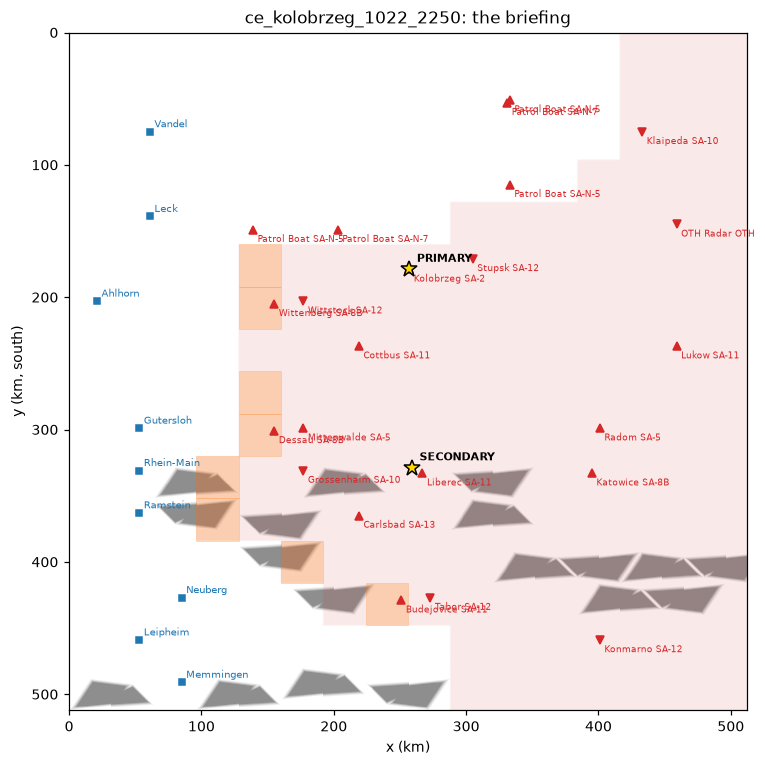

In [6]:
fig, ax = show_map(f'{PLAN}: the briefing', size=(8, 8))

## 2. "Is the plane seen?" — the radar model
`RadarModel.margins` is the game's own formula (`rules/radar.py`): `return + EMV - 100 > 0` means a site sees the plane on a pulse. EMV rises with altitude, speed and bank. Below,
the number of sites that would see a 190 kt plane at 250 ft heading east, over every cell of the map. The router pays for each expected seen pulse (`pulse_cost_samples`).

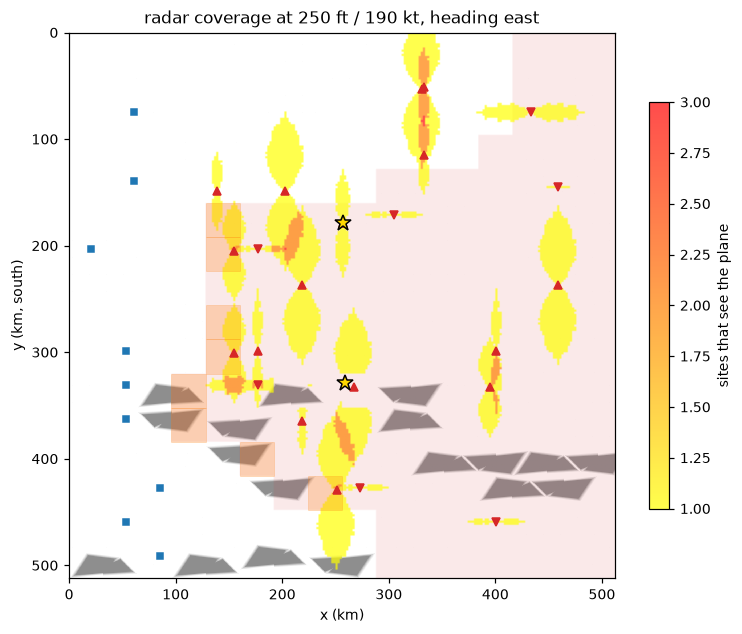

In [7]:
W, RM = pl.W, pl.RM
L = int(W.size / K); step = 2                                   # km per pixel
gx, gy = np.meshgrid(np.arange(0, L, step) + step / 2, np.arange(0, L, step) + step / 2)
mg = RM.margins(gx.ravel() * K, gy.ravel() * K, 1.0, 0.0, kt=190, alt=250)
seen = (mg > 0).sum(0).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 8))
draw_world(ax, pl, terrain=True, labels=False)
im = ax.imshow(np.where(seen > 0, seen, np.nan), cmap="autumn_r", alpha=.7, extent=(0, L, L, 0)); plt.colorbar(im, shrink=.6, label="sites that see the plane")
ax.set_title("radar coverage at 250 ft / 190 kt, heading east"); plt.show()

**Aspect matters.** The same site type sees a plane very differently head-on and side-on (pulse radars are blind head-on, doppler on the beam):

In [8]:
kinds = sorted({r["kind"] for r in W.radars})
print(f"{'site kind':>9s} {'system':10s} {'radial km':>10s} {'side km':>8s}")
for k in kinds:
    name = next(r["system"] for r in W.radars if r["kind"] == k)
    print(f"{k:9d} {name:10s} {str(RM.detection_range_km(k, 'radial', 190)):>10s} {str(RM.detection_range_km(k, 'side', 190)):>8s}")

site kind system      radial km  side km
        1 SA-2             None     65.5
        2 SA-5             None     87.5
        3 SA-8B            None     54.5
        4 SA-10            85.5     None
        5 SA-11            None     87.5
        6 SA-12            61.5     None
        7 SA-13            None     40.5
        9 SA-N-5           None     48.5
       11 SA-N-7           None     87.5
       21 OTH              72.5     None


## 3. One route: `Planner.plan(sequence)`
A *sequence* is takeoff piece, targets (with their attack geometry), landing piece. `plan` searches a grid path between consecutive pieces (A* priced in transit-km),
`reduce`s it to a few corners, `repair`s turn radii, densifies, `validate`s (walls, SA-14, target overflight) and walks it in game time for **fuel, speed and altitude**.
Here we plan the sequence the stored route chose and compare with what was stored.

planned in 1.7 s; errors: none; cost 1510; roles ['primary', 'secondary']
fuel: 13800 lb loaded -> 1694 lb at landing, 195 game min


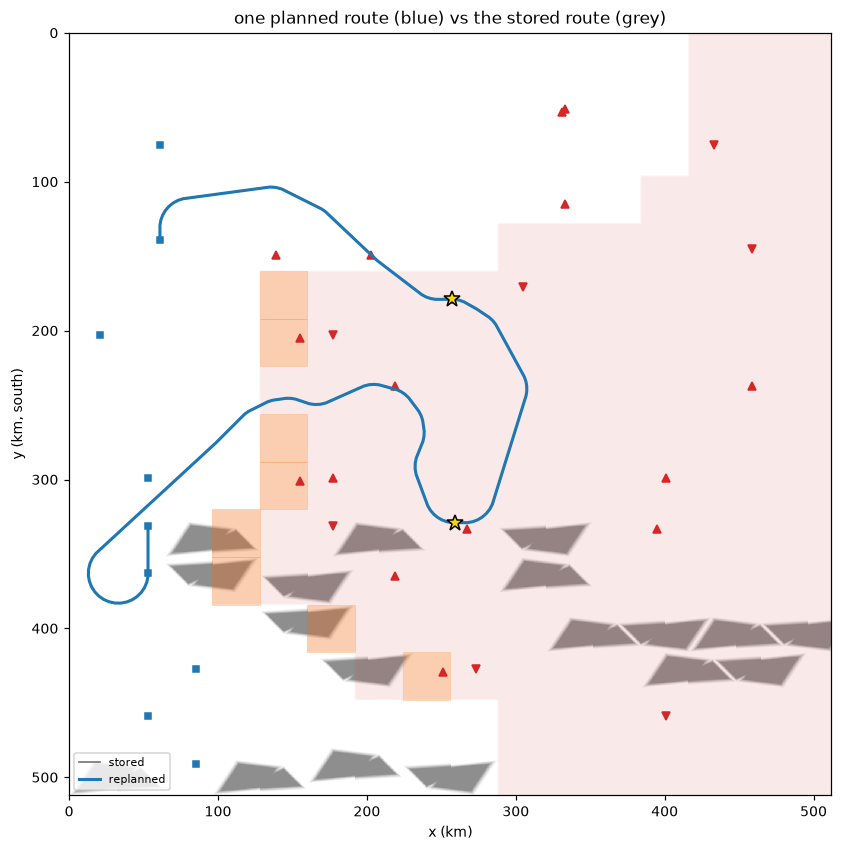

In [9]:
seq = chosen_sequence(pl, stored["chosen"])
t0 = time.time(); r = pl.plan(seq); print(f"planned in {time.time()-t0:.1f} s; errors: {r['errors'] or 'none'}; cost {r['cost']:.0f}; roles {sorted(r['roles'])}")
fu = r["fuel"]; print(f"fuel: {fu['fuel0']:.0f} lb loaded -> {fu['fuel_land']:.0f} lb at landing, {fu['t_end']/60:.0f} game min")
fig, ax = show_map("one planned route (blue) vs the stored route (grey)", routes=[dict(pts=stored["points"], color="grey", lw=1.2, label="stored"), dict(pts=r["pts"], color="C0", lw=2, label="replanned")], labels=False)

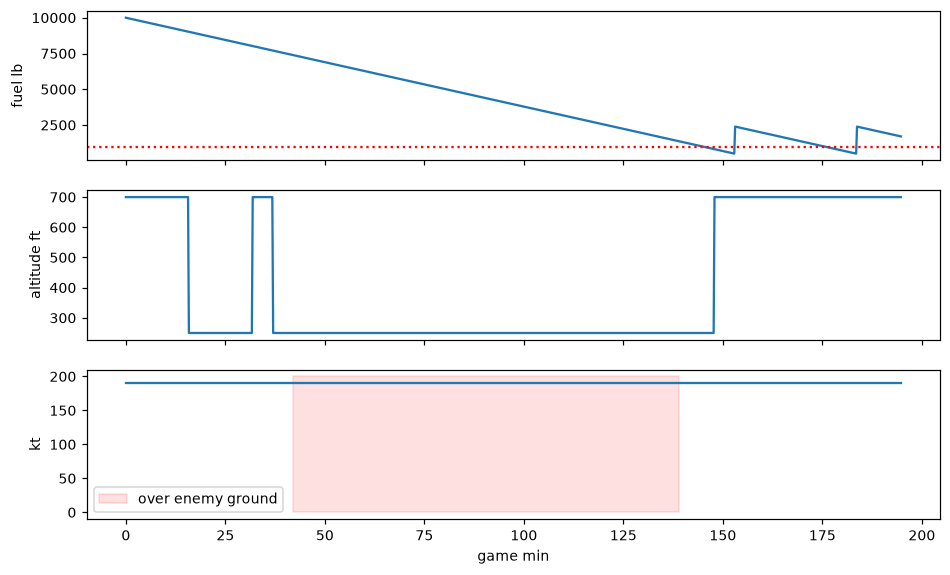

In [10]:
st = fu["steps"]; t = np.array([s["t"] for s in st]) / 60
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
axs[0].plot(t, [s["fuel"] for s in st]); axs[0].axhline(pl.P["landing_reserve_lb"], c="r", ls=":"); axs[0].set_ylabel("fuel lb")
axs[1].plot(t, [s["alt"] for s in st]); axs[1].set_ylabel("altitude ft")
axs[2].plot(t, [s["kt"] for s in st]); axs[2].fill_between(t, 0, 200, where=[bool(s["enemy"]) for s in st], color="r", alpha=.12, label="over enemy ground"); axs[2].set_ylabel("kt"); axs[2].set_xlabel("game min"); axs[2].legend()
plt.show()

## 4. What the radars do with it: the alert simulation
`alertsim.simulate` runs every site pulse by pulse over the timed route (48 scenarios for the unknown pulse phases): +alert when seen, a **network alert** above 0x7F (which
scrambles and sends the fighters hunting), launches above 0xC0 in SAM range, radar IDs near 0xFA. SA-14 cells in daylight add launches. The new `net` key lists, per scenario, when a network alert was raised.

{'p_any_net': 0.88, 'p_any_launch': 0.35, 'expected_ids': 0.69, 'max_alert': 255}
scenarios with a network alert: 42/48; first alert at game min (median) 118


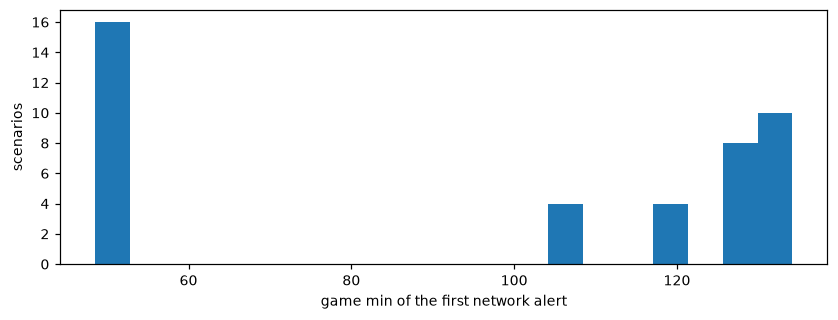

  Wittenberg SA-8B             p_net 0.54  p_launch 0.17  p_id 0.29  best margin +6
  Cottbus SA-11                p_net 0.35  p_launch 0.21  p_id 0.29  best margin +43
  Mittenwalde SA-5             p_net 0.48  p_launch 0.06  p_id 0.10  best margin +3
  Stupsk SA-12                 p_net 0.12  p_launch 0.00  p_id 0.00  best margin +11
  Patrol Boat SA-N-7           p_net 0.00  p_launch 0.00  p_id 0.00  best margin +7
  Budejovice SA-11             p_net 0.00  p_launch 0.00  p_id 0.00  best margin -21
  Carlsbad SA-13               p_net 0.00  p_launch 0.00  p_id 0.00  best margin -19
  Dessau SA-8B                 p_net 0.00  p_launch 0.00  p_id 0.00  best margin -7


In [11]:
sim = alertsim.simulate(pl.W, pl.RM, st)
e = sim["summary"]["expected"]; print({k: round(v, 2) for k, v in e.items()})
net = sim["net"]["expected"]; first = [n[0] / 60 for n in net if n]
print(f"scenarios with a network alert: {len(first)}/{len(net)}; first alert at game min (median) {np.median(first) if first else float('nan'):.0f}")
fig, ax = plt.subplots(figsize=(9, 3)); ax.hist(first, bins=20); ax.set_xlabel("game min of the first network alert"); ax.set_ylabel("scenarios"); plt.show()
top = sorted(sim["sites"], key=lambda s: -s["expected"]["mean_max"])[:8]
for s in top: print(f"  {s['name']:28s} p_net {s['expected']['p_net']:.2f}  p_launch {s['expected']['p_launch']:.2f}  p_id {s['expected']['p_id']:.2f}  best margin {s['best_margin']:+.0f}")

## 5. Options and the ranking seam
`Planner.run()` plans every combination of **target order x approach side x attack bearings** (the loiter is an opt-in post-pass; with `points`/`aircraft` a **primary-only** option is added), in a process pool with a shared
search memo, then hands the results to `Planner.rank(results)`. `rank` is the only place the objective enters. **Slow cell.**

In [12]:
RESULTS = {}
def plan_under(obj):
    spec_o = {**spec, "objective": obj}
    t0 = time.time(); res = api.plan_mission(spec_o, M, str(D)); return res, time.time() - t0
if RUN_SLOW:
    for obj in ("cost", "points", "aircraft"):
        RESULTS[obj] = plan_under(obj); res, dt = RESULTS[obj]
        print(f"{obj:9s} {dt:5.1f} s  valid={res.valid}  {res.best['tag']}")
else: print("set RUN_SLOW = True (about 2-3 min for the three plans)")

cost       24.4 s  valid=True  order primary/secondary, approach S, primary photo on 90, secondary photo on 270


points     48.6 s  valid=True  order primary, approach N, primary photo on 120


aircraft   49.5 s  valid=True  order primary/secondary, approach N, primary photo on 120, secondary photo on 270


### What each objective optimises
* **cost**: route cost in transit-km: fuel, enemy-cell samples, seen pulses, SA-14 minutes, corners. Never looks at what the pulses lead to.
* **points**: `E[points] - lambda * P(death)` along the timed route. Score = M x (samples + 140 primary + 35 secondary - 10 per radar ID - 20 per visual ID). Hits arrive at a constant rate per airborne minute
  (Veteran 0.0003, Elite 0.029, counted from the logs); a hit breaks the bay doors (bail out, score x 2/8) or the fuel tank (shorter flight) with decoded probabilities.
* **aircraft**: the same value, but hits come from the fighter model: the route's own network alerts send the fighters hunting, and their radars decide whether they see us.

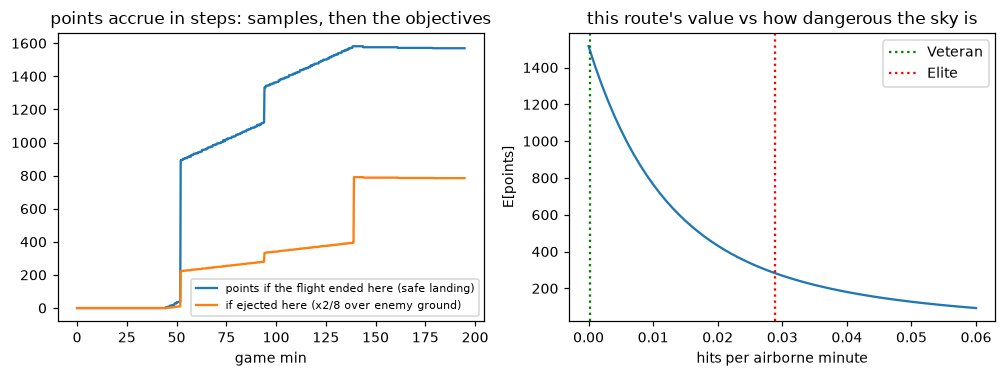

In [13]:
A = pl.assumptions(); T_ = points.terms(pl, r, sim, r["roles"]); ac = points.accrual(pl, r, T_, A)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(ac["t"] / 60, ac["pts"], label="points if the flight ended here (safe landing)"); axs[0].plot(ac["t"] / 60, ac["pts"] * ac["em"], label="if ejected here (x2/8 over enemy ground)")
axs[0].set_xlabel("game min"); axs[0].legend(fontsize=7); axs[0].set_title("points accrue in steps: samples, then the objectives")
hz = np.linspace(0, 0.06, 61)
vals = [points.value(ac, T_, points.Assumptions(hit_per_min=h), pl.W.opp, points.constant_hazard(ac, h))["exp_pts"] for h in hz]
axs[1].plot(hz, vals); axs[1].axvline(points.HIT_PER_MIN[2], c="g", ls=":", label="Veteran"); axs[1].axvline(points.HIT_PER_MIN[3], c="r", ls=":", label="Elite")
axs[1].set_xlabel("hits per airborne minute"); axs[1].set_ylabel("E[points]"); axs[1].legend(); axs[1].set_title("this route's value vs how dangerous the sky is"); plt.show()

## 6. The enemy aircraft
Facts from `docs/game/aircraft.md`: each type has its own radar (pulse: blind head-on and tail-on; doppler: blind on the beam), speed, and missile. Detection range of an F-19 at 250 ft / 190 kt, by type, aspect and difficulty:

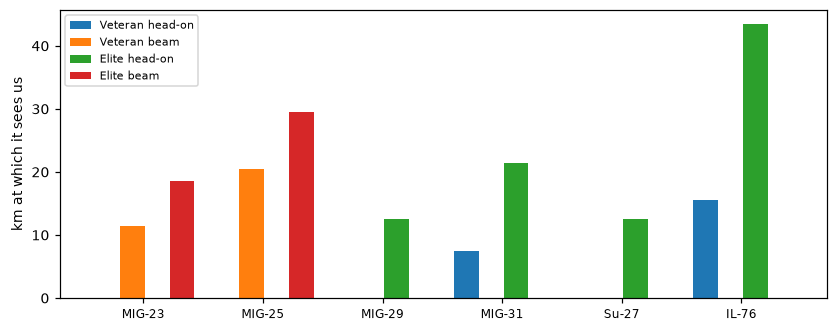

In [14]:
def aircraft_range(typ, aspect, opp, kt=190, alt=250):
    sp = rg.aircraft_spec(typ)
    if not sp.get("radar_type"): return 0.0
    best = 0.0
    for d in np.arange(0.5, 120, 0.5):
        hd = 0x4000 if aspect == "head-on" else 0 if aspect == "beam" else 0x4000
        sx, sy = ((d * 64, 0) if aspect != "tail" else (-d * 64, 0))
        s = rg.site_return(int(d * 64) if aspect != "tail" else int(d * 64), 0, alt, hd, kt, opp, 8, 0, 0, sp["radar_type"], 5000)
        if s + rg.emv(alt, kt, opp) > 100: best = d
    return best
types = [0, 1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(9, 3.4)); w = .27
for j, opp in enumerate((2, 3)):
    for i, asp in enumerate(("head-on", "beam")):
        ax.bar(np.arange(len(types)) + (j * 2 + i) * w / 1.3 - .3, [aircraft_range(t, asp, opp) for t in types], w / 1.3, label=f"{('Veteran','Elite')[j]} {asp}")
ax.set_xticks(range(len(types))); ax.set_xticklabels([rg.aircraft_spec(t)["name"] for t in types], fontsize=8); ax.set_ylabel("km at which it sees us"); ax.legend(fontsize=7); plt.show()

### The fighter model, one hunter at a time
A network alert makes airborne fighters fly straight at us. Every 32 s their radar sees us or not (alert +80 Elite / +64 Veteran seen, -32 unseen); above 0xC0 and inside 8 km: visual ID and a missile.
One MiG-31 starting 40 km ahead of a plane flying east (`fighters._hunter`, 200 draws):

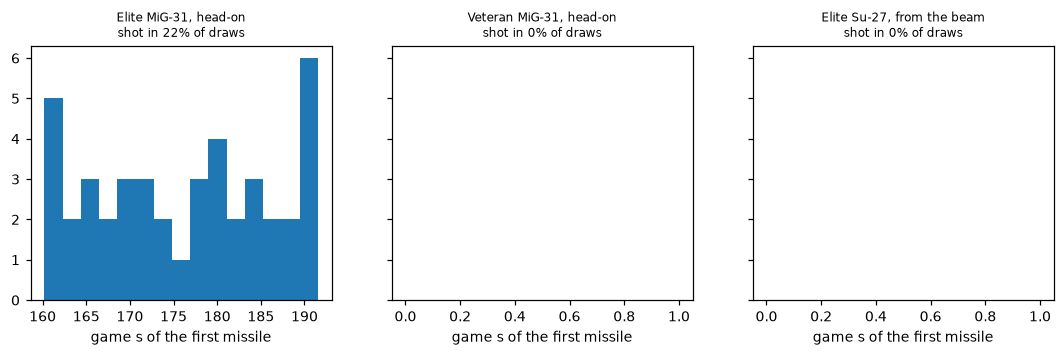

In [15]:
def draws(typ, opp, bearing, d0=40.0, n=200):
    spec_ = rg.aircraft_spec(typ); n_ = 160
    tt = np.arange(n_) * 16.0
    A_ = dict(t=tt, x=np.full(n_, 8000.0), y=np.full(n_, 8000.0), ux=np.ones(n_), uy=np.zeros(n_), kt=np.full(n_, 190.0), alt=np.full(n_, 250.0),
              emv=np.full(n_, float(rg.emv(250, 190, opp))), hdg=np.full(n_, 0x4000, np.int64), clutter=np.full(n_, 8))
    out = []
    for sd in range(n):
        shots, vis = [], []
        fighters._hunter(A_, spec_, typ, d0, bearing, [0.0], np.random.default_rng(sd), opp, opp * 16 + 32, 8.0, fighters.HUNT, 2500.0, shots, vis)
        out.append((shots[0][0] if shots else np.nan, vis[0] if vis else np.nan))
    return np.array(out)
fig, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (typ, opp, b, ttl) in zip(axs, [(3, 3, 0.0, "Elite MiG-31, head-on"), (3, 2, 0.0, "Veteran MiG-31, head-on"), (4, 3, np.pi / 2, "Elite Su-27, from the beam")]):
    o = draws(typ, opp, b); ax.hist(o[:, 0][~np.isnan(o[:, 0])], bins=15); ax.set_title(f"{ttl}\nshot in {np.mean(~np.isnan(o[:, 0])):.0%} of draws", fontsize=8); ax.set_xlabel("game s of the first missile")
plt.show()

fighter model on this route: {'shots': 0.2708333333333333, 'visual_ids': 0.20833333333333334, 'p_shot': 0.1875, 'scenarios': 48}


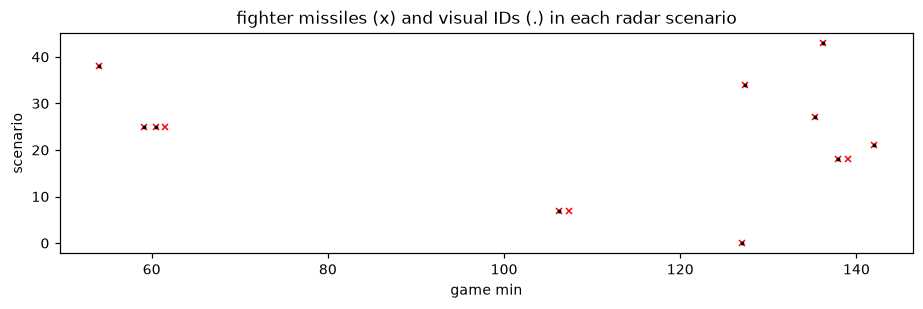

In [16]:
scen = fighters.simulate(pl.W, pl.RM, st, net, pl.th)
print("fighter model on this route:", fighters.summary(scen))
fig, ax = plt.subplots(figsize=(10, 2.6))
for i, s_ in enumerate(scen):
    ax.plot([t_ / 60 for t_, _ in s_["shots"]], [i] * len(s_["shots"]), "rx", ms=4)
    ax.plot([t_ / 60 for t_ in s_["visual"]], [i] * len(s_["visual"]), "k.", ms=3)
ax.set_xlabel("game min"); ax.set_ylabel("scenario"); ax.set_title("fighter missiles (x) and visual IDs (.) in each radar scenario"); plt.show()

**What is measured and what is assumed.** Measured: airborne fighter counts (CE), types, speeds, radar rules, the Elite hit rate (10 of 23 launches, no countermeasures). Assumed: the hunt lasts ~500 s after a network alert,
two shots per fighter, an orbit at 2 km with random aspect once close. Not modelled: alert-gated scrambles, patrol sightings, countermeasures. The model predicts far fewer shots than the logged Elite flights — treat its absolute numbers with suspicion, its *ranking* with some.

## 7. Comparing the objectives on a whole mission (slow)
The chosen route of each objective, scored under both points models. This is `scripts/compare_objectives.py` in a cell.

chosen by   min              roles   E[pts] flat hazard   E[pts] aircraft  shots


cost        195  primary+secondary                  284              1448  0.27


points      120            primary                  344              1048  0.19


aircraft    165  primary+secondary                  313              1516  0.19


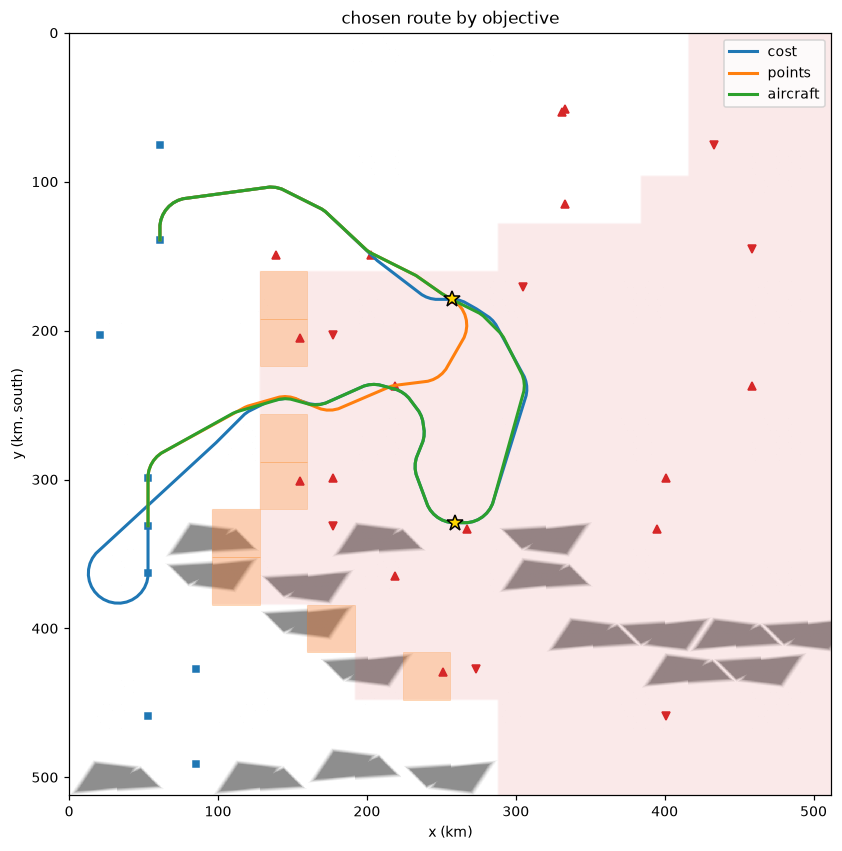

In [17]:
if RESULTS:
    import sys
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "compare_objectives.py").exists()) / "scripts"))
    from compare_objectives import evaluate
    print(f"{'chosen by':10s} {'min':>4s} {'roles':>18s} {'E[pts] flat hazard':>20s} {'E[pts] aircraft':>17s}  shots")
    for obj, (res, _) in RESULTS.items():
        ev = {o: evaluate(res.planner, res.best, o) for o in ("points", "aircraft")}
        print(f"{obj:10s} {ev['aircraft']['minutes']:4.0f} {'+'.join(ev['aircraft']['roles']):>18s} {ev['points']['exp_pts']:20.0f} {ev['aircraft']['exp_pts']:17.0f}  {ev['aircraft']['shots']:.2f}")
    fig, ax = plt.subplots(figsize=(9, 9)); draw_world(ax, RESULTS['cost'][0].planner, labels=False)
    for (obj, (res, _)), col in zip(RESULTS.items(), ("C0", "C1", "C2")):
        xy = xy_of(res.best["pts"]); ax.plot(xy[:, 0], xy[:, 1], c=col, lw=2, label=obj)
    ax.legend(); ax.set_title("chosen route by objective"); plt.show()
else: print("run the slow cell in section 5 first")

## 8. Flying it
```
# 1) on the briefing screen, with F-19 running (reads the mission, plans, writes route.json):
uv run python analysis/planner/new_plan.py --objective aircraft --opponent veteran --extra-fuel 2 --profile stealth
# 2) fly the route it prints (you watch the game; this sends keys):
uv run python -m f19.cli.fly --route <plan dir>/route.json --auto --hdg --memlog --director
# read-only dry run against the live game first: add --no-keys
```
`--objective cost|points|aircraft` is the only change from the old planner; the route.json format is the same.